# Entraînement des modèles sur Google Colab

Ce notebook entraîne nos modèles sur un **GPU gratuit de Google**, à la place de la carte graphique du PC, qui plante sous une charge longue (voir le journal des décisions, D9 et D10). Le code exécuté est **exactement celui du projet** : les scripts de `scripts/` et les réglages de `configs/`.

Le dossier **`Mon Drive/projet_avions`** est une copie exacte du projet sur le PC, avec les mêmes dossiers : `src/`, `scripts/`, `configs/`, `data/`, `docs/`, etc. Il est tenu à jour par `uv run python scripts/sync_drive.py`.

**Dans Colab :**
1. Ouvrir ce notebook depuis le Drive : `projet_avions/notebooks/colab_entrainement.ipynb`, double-clic, puis « Ouvrir avec Google Colaboratory ».
2. Vérifier que Colab utilise un GPU : menu **Exécution → Modifier le type d'exécution → GPU**.
3. Exécuter les cellules **une par une, dans l'ordre** (`Maj + Entrée`).
4. Les résultats arrivent dans les mêmes dossiers que sur le PC :
   - `projet_avions/runs/` : courbes et métriques ;
   - `projet_avions/models/` : poids des modèles entraînés.

**Ensuite, sur le PC :** `uv run python scripts/sync_drive.py` ramène les nouveaux modèles et résultats dans le projet.

## 1. Vérifier le GPU

Le résultat doit afficher une carte, par exemple `Tesla T4`. Si le GPU n'est pas disponible, change le type d'exécution (voir plus haut), puis relance cette cellule.

In [1]:
import torch

if torch.cuda.is_available():
    print("GPU disponible :", torch.cuda.get_device_name(0))
else:
    print("PAS DE GPU : menu Exécution > Modifier le type d'exécution > GPU T4, puis relancer")

GPU disponible : Tesla T4


## 2. Connecter Google Drive

Une fenêtre demande l'autorisation d'accéder à ton Drive : accepte-la, c'est là que sont tes fichiers et que les résultats seront enregistrés.

In [2]:
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/projet_avions"  # le projet, synchronisé depuis le PC
PROJET = (
    "/content/projet_ia"  # copie de travail du projet dans Colab (effacée à la fin de la session)
)

Mounted at /content/drive


## 3. Copier le projet sur le disque de Colab

On travaille sur une copie locale, bien plus rapide que le Drive pour lire les images pendant l'entraînement. Cette étape prend 1 à 3 minutes.

`runs/` et `models/` ne sont pas copiés : les résultats de l'entraînement seront écrits **directement sur le Drive**.

In [3]:
import shutil

shutil.rmtree(PROJET, ignore_errors=True)
shutil.copytree(
    DRIVE_DIR,
    PROJET,
    ignore=shutil.ignore_patterns("runs", "models", "yolo", "weights", ".ipynb_checkpoints"),
)
!echo "Images : $(ls {PROJET}/data/raw/images | wc -l)  |  annotations : $(ls {PROJET}/data/raw/annotations | wc -l)"

Images : 1331  |  annotations : 1331


## 4. Installer les bibliothèques

Colab a déjà PyTorch, pandas, OpenCV et scikit-learn. Il manque seulement **Ultralytics**, installé dans la même version que sur le PC.

`PYTHONPATH` indique à Python où trouver notre propre code (`src/avions`).

In [4]:
!pip install -q "ultralytics==8.4.189"

import os

os.environ["PYTHONPATH"] = f"{PROJET}/src"
os.chdir(PROJET)
!python -c "import avions, ultralytics; print('Projet et Ultralytics', ultralytics.__version__, 'prêts')"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Projet et Ultralytics 8.4.189 prêts


## 5. Préparer le dataset au format YOLO

C'est le même script que sur le PC. Il convertit les annotations et range les images selon le découpage train / validation / test.

In [5]:
!python scripts/prepare_yolo.py

Dataset YOLO écrit : /content/projet_ia/data/yolo
  train : 1070 images, 6295 avions
  val   :  130 images,  787 avions
  test  :  131 images,  788 avions


## 6. Choisir ce qu'on entraîne

On entraîne les **deux détecteurs** l'un après l'autre, avec les réglages de `configs/` :
1. `detecteur_1classe` : l'étage 1 de notre architecture, qui trouve les avions ;
2. `detecteur_20classes` : le témoin end-to-end, pour comparer.

Comptez 30 à 45 minutes chacun sur un GPU T4, et moins sur un GPU plus récent (L4, A100).

Si l'un des deux est déjà terminé (son fichier `.pt` est dans `projet_avions/models/`), retire-le de la liste `CONFIGS`.

In [6]:
import os
from pathlib import Path

import yaml

CONFIGS = ["configs/detecteur_1classe.yaml", "configs/detecteur_20classes.yaml"]
WORKERS = min(8, os.cpu_count())  # processus qui chargent les images, selon la machine Colab


def nom_du_modele(config):
    # Le nom défini dans le fichier de configuration (ex. "detecteur_1classe")
    return yaml.safe_load(Path(config).read_text(encoding="utf-8"))["name"]

## 7. Lancer les entraînements

- Les courbes et les métriques sont écrites **directement sur le Drive**, dans `runs/`. Si Colab se déconnecte, rien n'est perdu : voir la cellule 7 bis.
- Les poids de chaque modèle sont copiés dans `projet_avions/models/` **dès la fin de son entraînement**.

In [7]:
for config in CONFIGS:
    nom = nom_du_modele(config)
    print(f"===== Entraînement : {nom} =====")
    !python scripts/train_detector.py {config} workers={WORKERS} "project={DRIVE_DIR}/runs"
    !mkdir -p "{DRIVE_DIR}/models" && cp models/{nom}.pt "{DRIVE_DIR}/models/"

===== Entraînement : detecteur_1classe =====
New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/projet_ia/data/yolo/dataset.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=

### 7 bis. Seulement si Colab s'est déconnecté PENDANT un entraînement

> **Attention : ne pas exécuter cette cellule si l'entraînement est allé au bout.** Elle sert uniquement à reprendre un entraînement coupé. Le script refuse désormais de « reprendre » un entraînement terminé (voir l'incident D16 dans le journal des décisions).

Relance les cellules 1 à 6, indique ci-dessous la configuration interrompue, puis exécute cette cellule. L'entraînement reprend à la dernière epoch enregistrée sur le Drive, au lieu de tout recommencer.

Si l'autre détecteur n'a pas encore été entraîné, relance ensuite la cellule 7 en ne gardant que lui dans `CONFIGS`.

In [8]:
CONFIG_INTERROMPUE = "configs/detecteur_1classe.yaml"

nom = nom_du_modele(CONFIG_INTERROMPUE)
!python scripts/train_detector.py {CONFIG_INTERROMPUE} --resume workers={WORKERS} "project={DRIVE_DIR}/runs"
!mkdir -p "{DRIVE_DIR}/models" && cp models/{nom}.pt "{DRIVE_DIR}/models/"

New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
WARNING ⚠️ model '/content/drive/MyDrive/projet_avions/runs/detecteur_1classe/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud

## 8. Résultats

Pour chaque détecteur, on affiche les scores de sa meilleure epoch sur la **validation**, puis ses courbes d'apprentissage. Copie ces lignes de scores pour Claude.

Sur le PC, `uv run python scripts/sync_drive.py` ramène ensuite les modèles dans `models/` et les courbes dans `runs/`.

detecteur_1classe : meilleure epoch 52 sur 67 | précision 0.987 | rappel 0.997 | mAP50 0.993 | mAP50-95 0.807


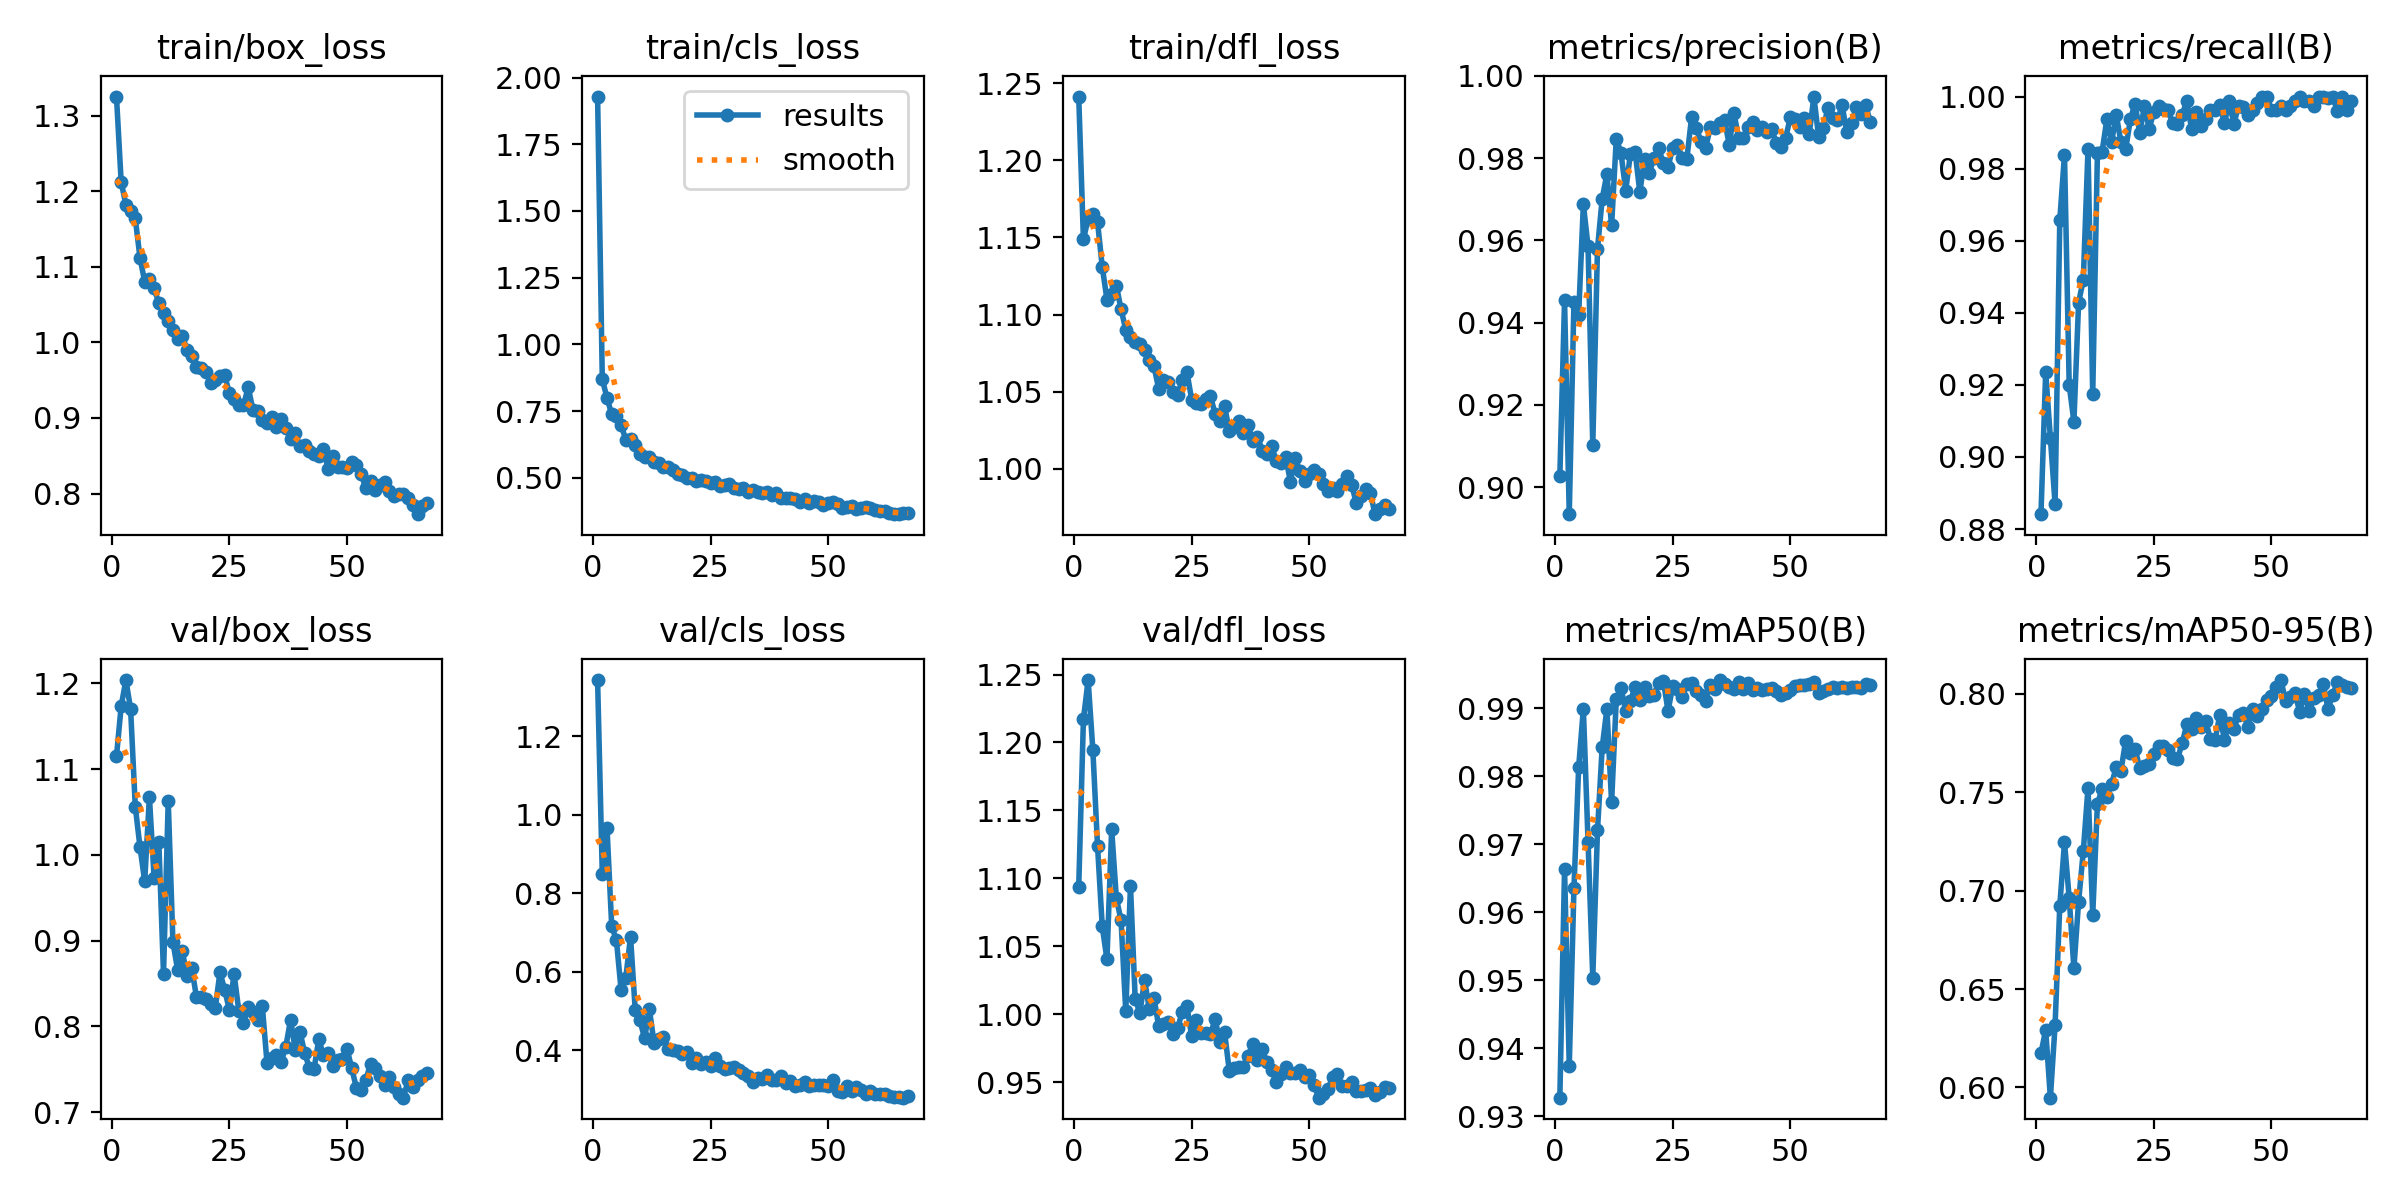

detecteur_20classes : meilleure epoch 69 sur 80 | précision 0.978 | rappel 0.966 | mAP50 0.986 | mAP50-95 0.817


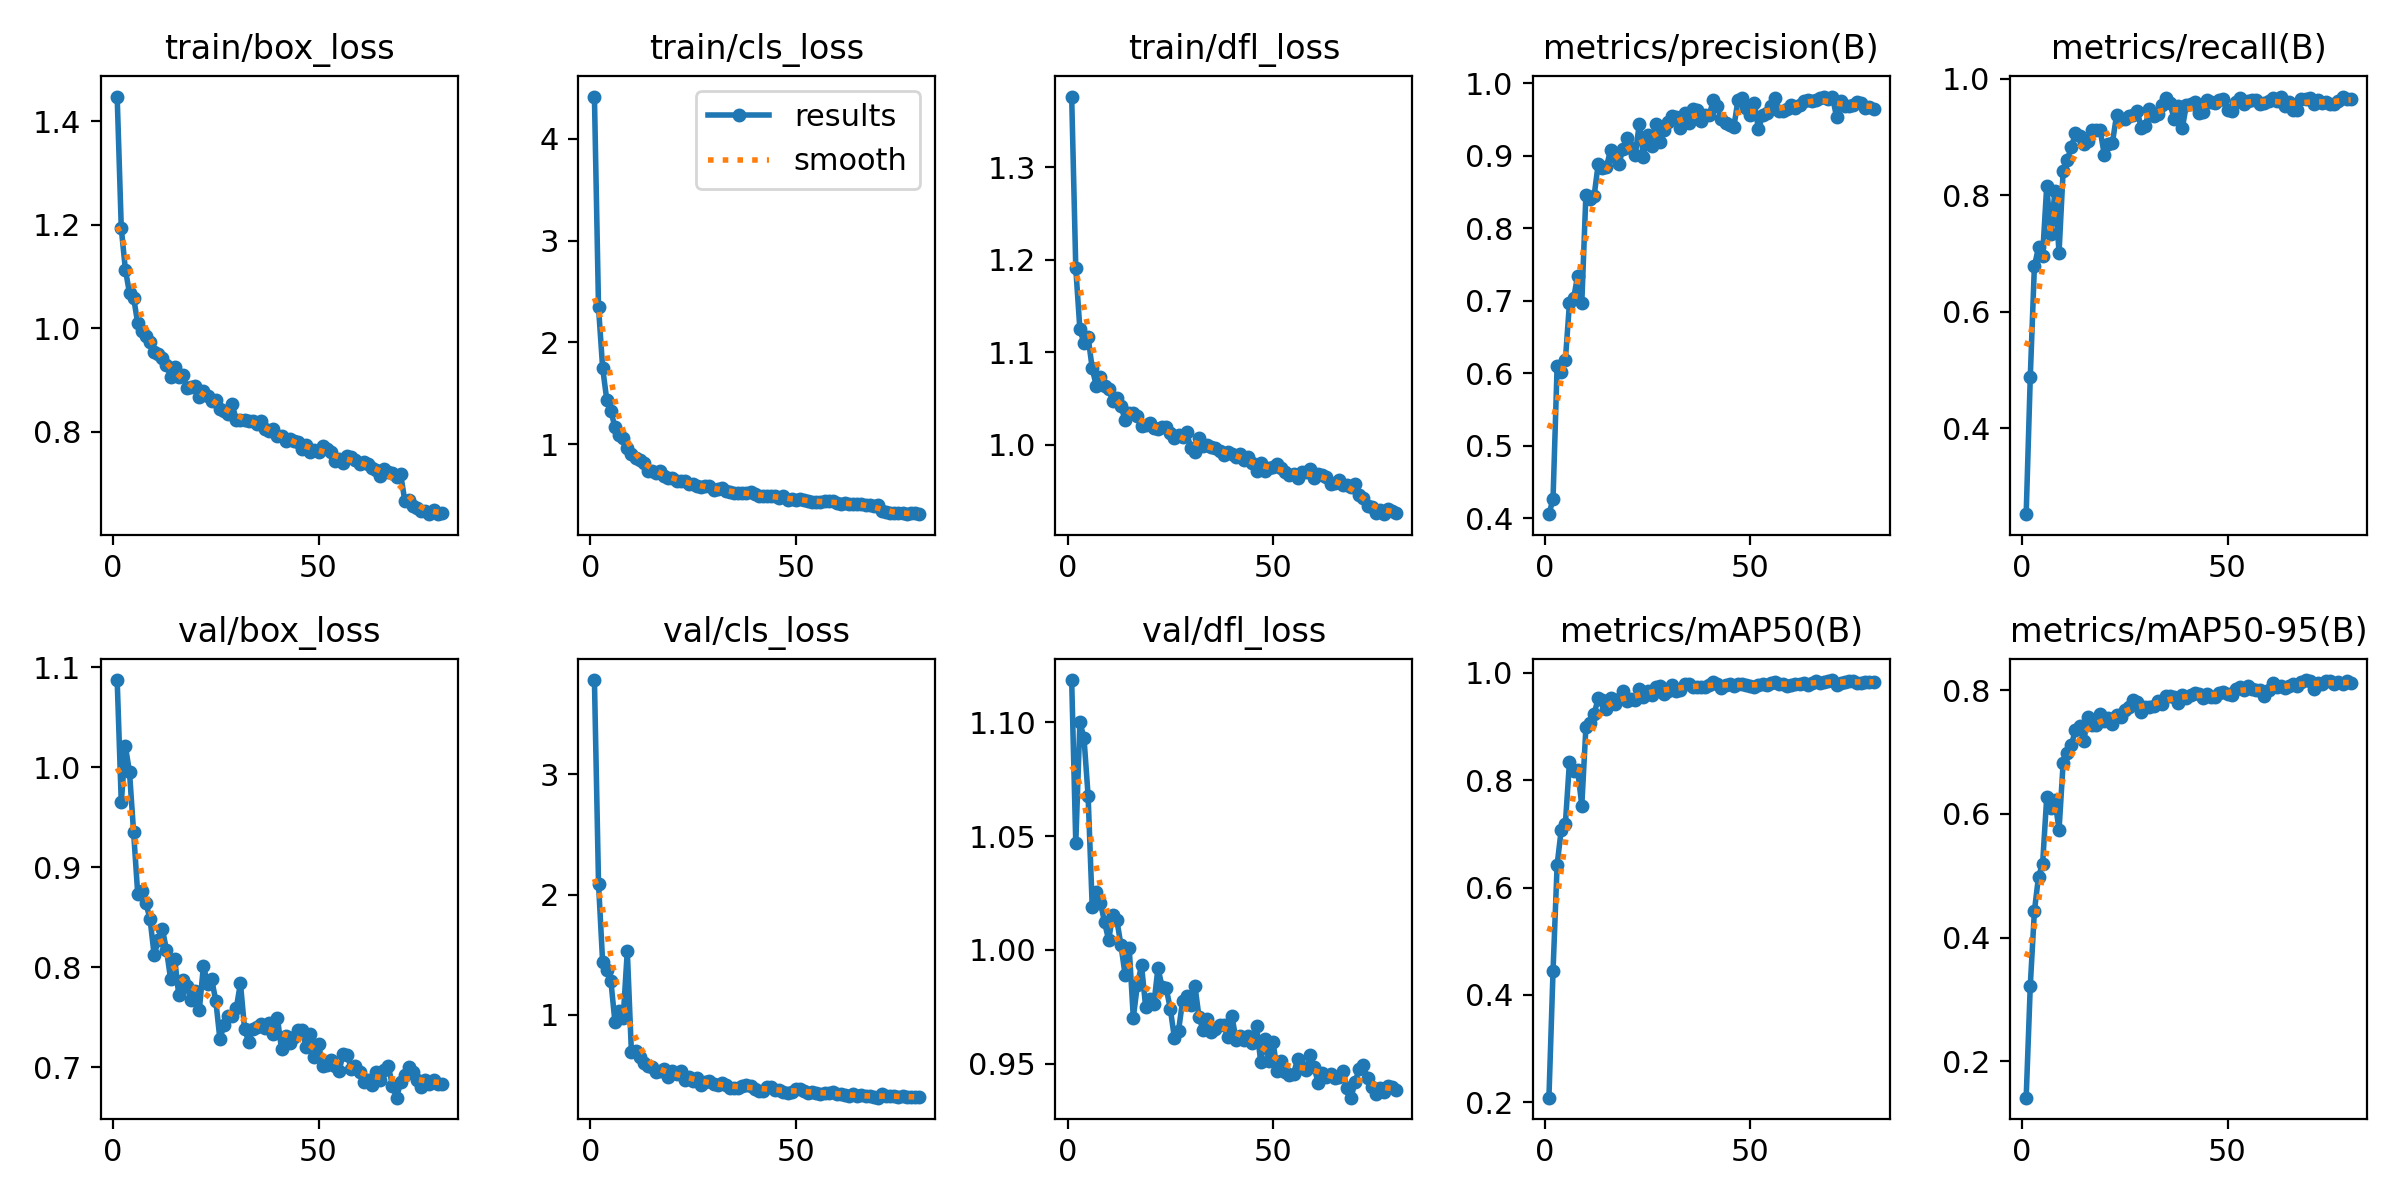

In [9]:
import pandas as pd
from IPython.display import Image, display

for config in CONFIGS:
    nom = nom_du_modele(config)
    resultats = pd.read_csv(f"{DRIVE_DIR}/runs/{nom}/results.csv")
    resultats.columns = resultats.columns.str.strip()
    best = resultats.loc[resultats["metrics/mAP50-95(B)"].idxmax()]
    print(
        f"{nom} : meilleure epoch {int(best['epoch'])} sur {len(resultats)}"
        f" | précision {best['metrics/precision(B)']:.3f}"
        f" | rappel {best['metrics/recall(B)']:.3f}"
        f" | mAP50 {best['metrics/mAP50(B)']:.3f}"
        f" | mAP50-95 {best['metrics/mAP50-95(B)']:.3f}"
    )
    display(Image(f"{DRIVE_DIR}/runs/{nom}/results.png"))  # courbes d'apprentissage